In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib
import yfinance as yf

Using matplotlib backend: module://matplotlib_inline.backend_inline


Question One

In [2]:
x = np.linspace(-2, 2, 1000)

In [3]:
f_x= np.sqrt(2*np.abs(x) - x**2)

In [4]:
g_x= -2.14 * np.sqrt(np.sqrt(2) - np.sqrt(abs(x)))

In [5]:
plt.figure(figsize=(8, 8))

<Figure size 800x800 with 0 Axes>

<Figure size 800x800 with 0 Axes>

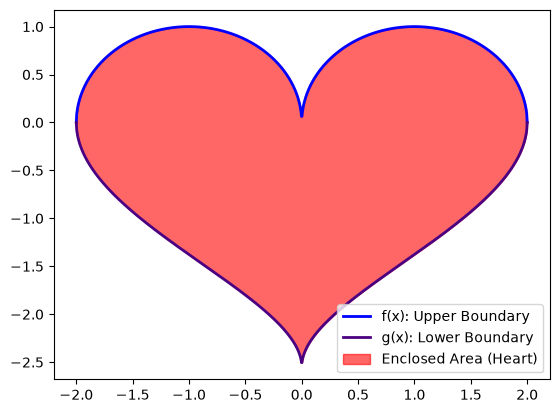

In [6]:
plt.plot(x, f_x, color="blue", linewidth=2, label="f(x): Upper Boundary")
plt.plot(x, g_x, color="indigo", linewidth=2, label="g(x): Lower Boundary")
plt.fill_between(x, f_x, g_x, color="red", alpha=0.6, label="Enclosed Area (Heart)")
plt.legend(loc="lower right")

Question Two: Dynamic Heart Shape Animation

In [7]:
x = np.linspace(-1.8, 1.8, 1000)

In [8]:
plt.figure(figsize=(8, 8))

<Figure size 800x800 with 0 Axes>

<Figure size 800x800 with 0 Axes>

In [9]:
for alpha in np.arange(0, 20.2, 0.2):
    plt.clf()
    f_x = np.cbrt(x**2) + 0.9 * np.sqrt(3.3 - x**2) * np.sin(alpha * np.pi * x)

<Figure size 640x480 with 0 Axes>

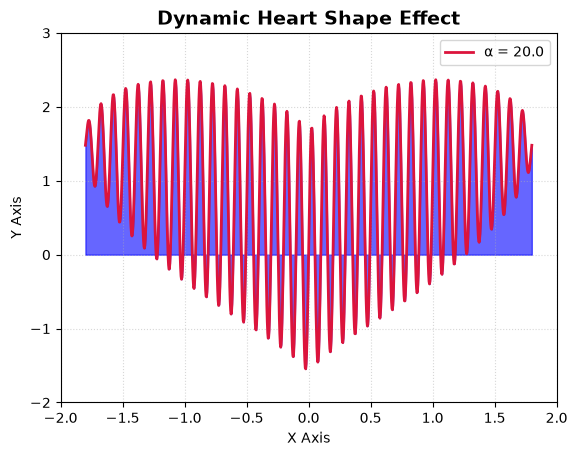

In [10]:
plt.plot(x, f_x, color="crimson", linewidth=2, label=f"α = {alpha:.1f}")
plt.fill_between(x, f_x, color="blue", alpha=0.6)
plt.title("Dynamic Heart Shape Effect", fontsize=14, fontweight='bold')
plt.xlabel("X Axis")
plt.ylabel("Y Axis")

plt.xlim(-2, 2)
plt.ylim(-2, 3)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(loc="upper right")

Question Three

In [11]:
import os

In [12]:
os.chdir("C:\DataSc")

In [13]:
df = pd.read_excel("Transcripts.xlsx")

In [14]:
df

,Student_Name,Mathematics,Economics,Science
0,Alice,68,58,44
1,Johnson,72,37,80
2,Charlie,50,82,48
3,Diana,92,89,65
4,Wright,40,71,51
5,Fiona,87,51,89
6,George,60,69,78
7,Hannah,77,75,66
8,Malcom,55,62,71
9,Jason,72,79,81


In [15]:
pass_mark = 50

In [16]:
courses = ["Mathematics", "Economics", "Science"]

In [17]:
passed_all = (df[courses] >= pass_mark).all(axis=1)
failed_students = df.loc[~passed_all, "Student_Name"].tolist()
print("Students who failed at least one course: ", failed_students)

Students who failed at least one course:  ['Alice', 'Johnson', 'Charlie', 'Wright']


In [18]:
df_pass = df[passed_all].reset_index(drop=True)
df_pass

,Student_Name,Mathematics,Economics,Science
0,Diana,92,89,65
1,Fiona,87,51,89
2,George,60,69,78
3,Hannah,77,75,66
4,Malcom,55,62,71
5,Jason,72,79,81


Average and Highest Grade for each subject

In [19]:
summary = df_pass[courses].agg(["mean", "max"]).T
summary.columns = ["Average Grade", "Highest Grade"]
summary.round(2)

,Average Grade,Highest Grade
Mathematics,73.83,92.0
Economics,70.83,89.0
Science,75.00,89.0


Ranking the remaining students by overall average

In [20]:
df_pass["Average"] = df_pass[courses].mean(axis=1)

In [21]:
ranking = df_pass[["Student_Name", "Average"]].sort_values("Average", ascending=False)

In [22]:
ranking["Rank"] = ranking["Average"].rank(ascending=False, method="min").astype(int).reset_index(drop=True)
ranking = ranking.reset_index(drop=True)
ranking.round(2)

,Student_Name,Average,Rank
0,Diana,82.00,1
1,Jason,77.33,6
2,Fiona,75.67,2
3,Hannah,72.67,4
4,George,69.00,3
5,Malcom,62.67,5


In [23]:
!pip install yfinance

Question Four

In [24]:
firm_data = [
    ("Boeing", "BA", "Defense"),
    ("General Dynamics", "GD", "Defense"),
    ("Raytheon", "RTX", "Defense"),
    ("Lockheed Martin", "LMT", "Defense"),
    ("Eli Lilly and Company", "LLY", "Pharmaceuticals"),
    ("Johnson & Johnson", "JNJ", "Pharmaceuticals"),
    ("AbbVie Inc.", "ABBV", "Pharmaceuticals"),
    ("Amgen Inc.", "AMGN", "Pharmaceuticals"),
    ("Gilead Sciences, Inc.", "GILD", "Pharmaceuticals"),
    ("Pfizer Inc.", "PFE", "Pharmaceuticals"),
    ("Bristol Myers Squibb", "BMY", "Pharmaceuticals"),
    ("ExxonMobil", "XOM", "Energy"),
    ("Chevron", "CVX", "Energy"),
    ("Occidental Petroleum", "OXY", "Energy"),
    ("Schlumberger / SLB", "SLB", "Energy"),
    ("Halliburton", "HAL", "Energy"),
    ("Coca Cola", "KO", "Soft Drinks"),
]

In [25]:
df_firms = pd.DataFrame(firm_data, columns=["Firm_Name", "Ticker", "Industry"])
tickers = df_firms["Ticker"].tolist()
df_firms

,Firm_Name,Ticker,Industry
0,Boeing,BA,Defense
1,General Dynamics,GD,Defense
2,Raytheon,RTX,Defense
3,Lockheed Martin,LMT,Defense
4,Eli Lilly and Company,LLY,Pharmaceuticals
5,Johnson & Johnson,JNJ,Pharmaceuticals
6,AbbVie Inc.,ABBV,Pharmaceuticals
7,Amgen Inc.,AMGN,Pharmaceuticals
8,"Gilead Sciences, Inc.",GILD,Pharmaceuticals
9,Pfizer Inc.,PFE,Pharmaceuticals


Downloading the closing prices from Yahoo!Finance:

In [26]:
start_date = "2021-01-01"
end_date = "2026-03-05"
price_data = yf.download(tickers, start=start_date, end=end_date, progress=False)
if isinstance(price_data.columns, pd.MultiIndex):
  prices = price_data["Close"]
else:
  prices = price_data[["Close"]] if "Close" in price_data.columns else price_data

prices = prices.dropna(how="all")

Plotting Prices:

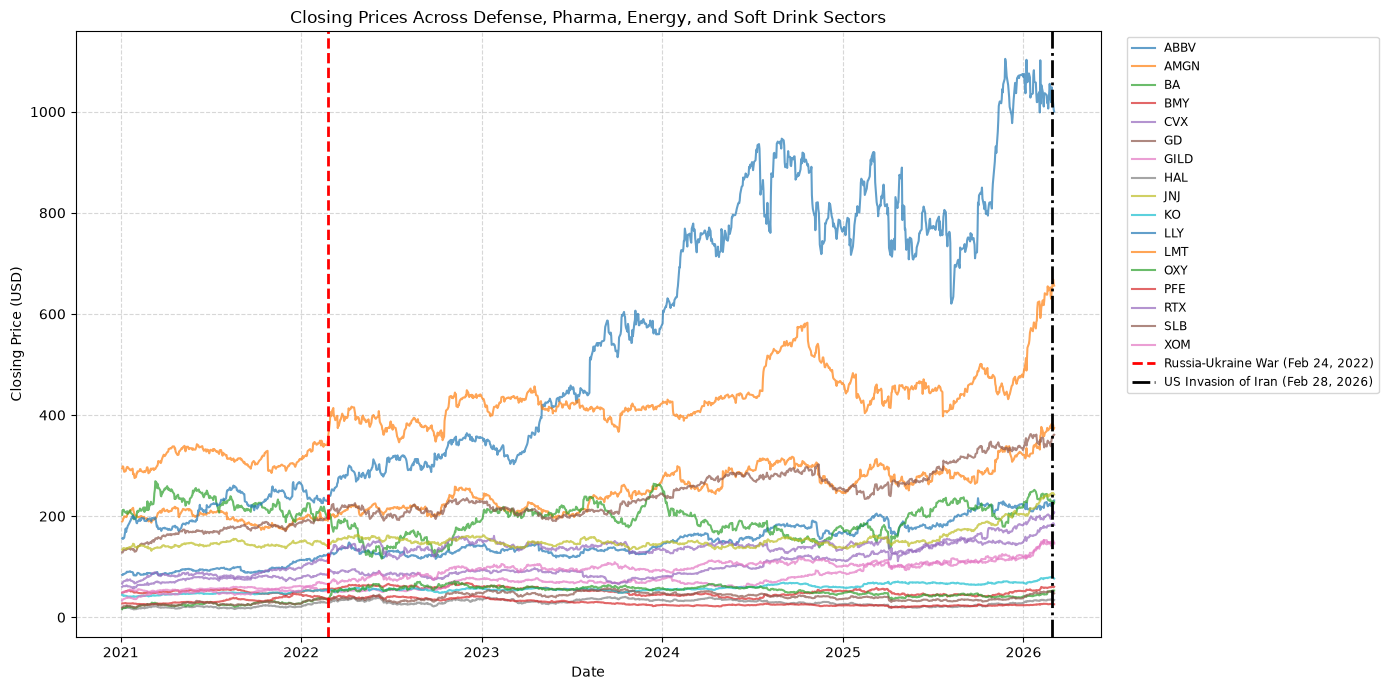

In [27]:
event1 = pd.to_datetime("2022-02-24")
event2 = pd.to_datetime("2026-02-28")

plt.figure(figsize=(14, 7))
for ticker in prices.columns:
  plt.plot(prices.index, prices[ticker], alpha=0.7, label=ticker)

plt.axvline(x=event1, color="red", linestyle="--", linewidth=2, label="Russia-Ukraine War (Feb 24, 2022)",)
plt.axvline(x=event2, color="black", linestyle="-.", linewidth=2, label="US Invasion of Iran (Feb 28, 2026)",)

plt.title("Closing Prices Across Defense, Pharma, Energy, and Soft Drink Sectors")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize="small")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Impact of the Geopolitical Events on Returns

The geopolitical events of February 24, 2022 (marking the start of the Russia-Ukraine conflict), and February 28, 2026, introduced immediate, sharp shocks to global markets. On and immediately following these dates, log returns and volatility surged significantly across the board as markets abruptly priced in heightened geopolitical risk, supply chain disruptions, and macroeconomic uncertainty.

The impact varied notably by sector. Defense and Energy Sectors typically experience positive return spikes and heightened trading volumes during major military conflicts due to anticipated surges in government defence spending and soaring commodity and oil prices.

Consumer Staples and Soft Drinks sectors generally show more muted reactions to geopolitical headlines, acting as safe havens, although broad market panics can still trigger short-term fluctuations before prices stabilise.

Computing and plotting the returns

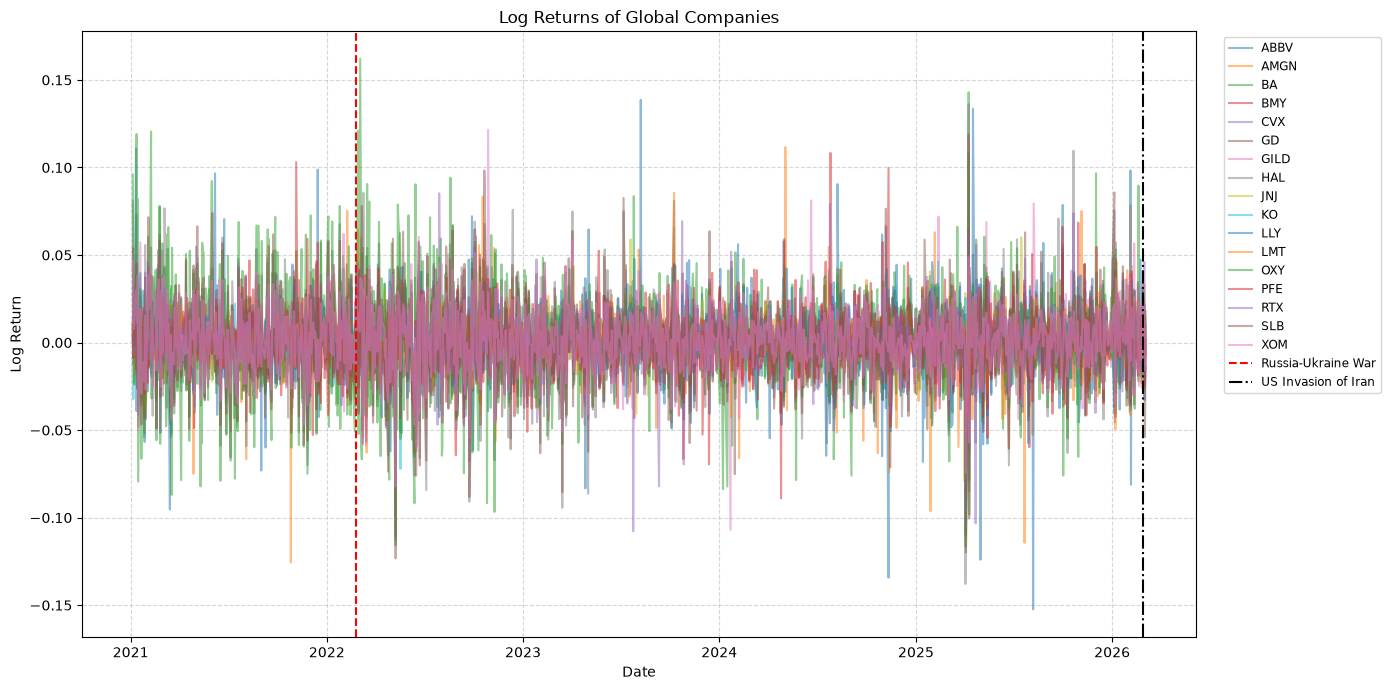

In [28]:
returns = np.log(prices / prices.shift(1)).dropna()

plt.figure(figsize=(14, 7))

for ticker in returns.columns:
  plt.plot(returns.index, returns[ticker], alpha=0.5, label=ticker)

plt.axvline(x=event1, color="red", linestyle="--", linewidth=1.5, label="Russia-Ukraine War")
plt.axvline(x=event2, color="black", linestyle="-.", linewidth=1.5, label="US Invasion of Iran",)

plt.title("Log Returns of Global Companies")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize="small")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


In [29]:
correlation_matrix = returns.corr()
print("\n--- Correlation Matrix Summary ---")
print(correlation_matrix.iloc[:7, :7])


--- Correlation Matrix Summary ---
Ticker      ABBV      AMGN        BA       BMY       CVX        GD      GILD
Ticker                                                                      
ABBV    1.000000  0.428524  0.107107  0.386864  0.185751  0.219590  0.350456
AMGN    0.428524  1.000000  0.110770  0.417834  0.151934  0.263571  0.451460
BA      0.107107  0.110770  1.000000  0.063486  0.291836  0.329891  0.140596
BMY     0.386864  0.417834  0.063486  1.000000  0.168451  0.214399  0.391199
CVX     0.185751  0.151934  0.291836  0.168451  1.000000  0.403960  0.138369
GD      0.219590  0.263571  0.329891  0.214399  0.403960  1.000000  0.221024
GILD    0.350456  0.451460  0.140596  0.391199  0.138369  0.221024  1.000000


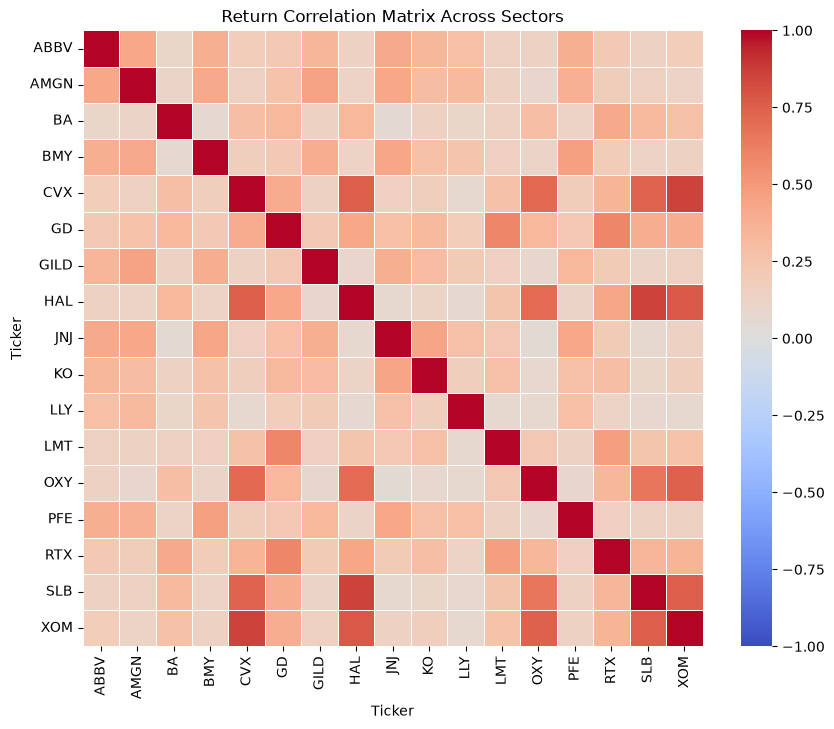

In [30]:
plt.figure(figsize=(10, 8))
import seaborn as sns
sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5,)
plt.title("Return Correlation Matrix Across Sectors")
plt.show()

Return Correlations and Patterns

When examining the correlation matrix of the companies' returns, a very distinct pattern emerges.

There was intra-sector clustering. That is, companies operating within the same industry exhibit strong positive correlations. For instance, defense contractors (such as Lockheed Martin and General Dynamics) move closely together, and major energy firms (such as ExxonMobil and Chevron) show high correlation coefficients. This happens because firms within the same sector respond in unison to identical fundamental drivers, commodity cycles, industry regulations, and sector-specific news.

In contrast, there was cross-sector divergence; that is, correlations between firms from entirely different industries—such as Defense versus Soft Drinks or Pharmaceuticals are markedly lower. This structural separation highlights the fundamental benefits of multi-industry portfolio diversification, as different sectors are driven by distinct macroeconomic factors and consumer demand cycles.